# Notebook 8 – Feature Scaling

## 1. Why feature scaling?
Features measured on very different scales can dominate distance-based or gradient-based algorithms. Scaling does not always help tree-based algorithms such as decision trees and random forests.

,tenure,MonthlyCharges
count,5.000000,5.000000
mean,26.600000,150.000000
std,22.799123,197.989899
min,1.000000,20.000000
25%,12.000000,50.000000
50%,24.000000,80.000000
75%,36.000000,100.000000
max,60.000000,500.000000


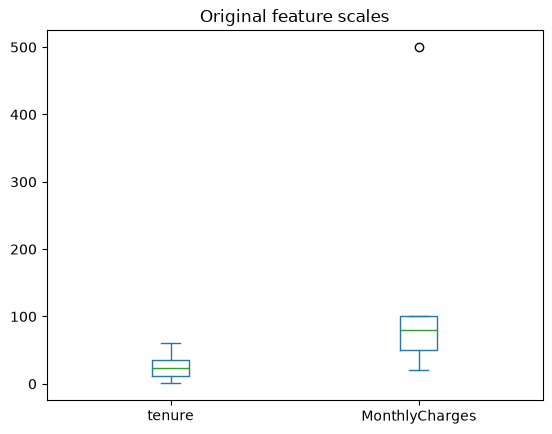

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler

df = pd.DataFrame({"tenure": [1, 12, 24, 36, 60], "MonthlyCharges": [20, 50, 80, 100, 500]})
display(df.describe())
df.plot(kind="box", title="Original feature scales")
plt.show()

## 2. Normalization and Min-Max scaling
Min-Max scaling maps values to a selected range, usually 0–1. It preserves relative ordering but is strongly affected by extreme values.

In [2]:
minmax = MinMaxScaler()
minmax_df = pd.DataFrame(minmax.fit_transform(df), columns=df.columns)
display(minmax_df)
print("Minimums:\n", minmax_df.min())
print("Maximums:\n", minmax_df.max())

,tenure,MonthlyCharges
0,0.000000,0.000000
1,0.186441,0.062500
2,0.389831,0.125000
3,0.593220,0.166667
4,1.000000,1.000000


Minimums:
 tenure            0.0
MonthlyCharges    0.0
dtype: float64
Maximums:
 tenure            1.0
MonthlyCharges    1.0
dtype: float64


## 3. Standardization and StandardScaler
Standardization subtracts the mean and divides by standard deviation. It often helps scale-sensitive algorithms, but outliers can strongly affect the mean and standard deviation.

In [3]:
standard = StandardScaler()
standard_df = pd.DataFrame(standard.fit_transform(df), columns=df.columns)
display(standard_df)
print("Means:", standard_df.mean().round(3).to_dict())
print("Standard deviations:", standard_df.std(ddof=0).round(3).to_dict())

,tenure,MonthlyCharges
0,-1.255385,-0.734100
1,-0.715962,-0.564692
2,-0.127500,-0.395285
3,0.460962,-0.282346
4,1.637885,1.976424


Means: {'tenure': -0.0, 'MonthlyCharges': 0.0}
Standard deviations: {'tenure': 1.0, 'MonthlyCharges': 1.0}


## 4. RobustScaler and MaxAbsScaler
RobustScaler uses the median and interquartile range, making it less sensitive to extreme values. MaxAbsScaler divides by the maximum absolute value and preserves sparsity for suitable data.

In [4]:
robust_df = pd.DataFrame(RobustScaler().fit_transform(df), columns=df.columns)
maxabs_df = pd.DataFrame(MaxAbsScaler().fit_transform(df), columns=df.columns)
display(robust_df)
display(maxabs_df)

,tenure,MonthlyCharges
0,-0.958333,-1.2
1,-0.500000,-0.6
2,0.000000,0.0
3,0.500000,0.4
4,1.500000,8.4


,tenure,MonthlyCharges
0,0.016667,0.04
1,0.200000,0.10
2,0.400000,0.16
3,0.600000,0.20
4,1.000000,1.00
